# RQ1: transfer and stability — final results

E1 learning rates and E2 training seeds are viewed together. E1 keeps full updates with L2-SP 0.003; RQ2 retains the complete factorial. Final evaluation averages five paired outer folds within table, then weights tables equally. AUC/R² gains are CPT minus original; Brier/RMSE gains reverse direction. RMSE gains here are relative percentages.

## 0. Evidence and interpretation

The selected local evidence is a snapshot. Missing evidence remains unavailable; queued VSC jobs are not completed results.

In [1]:
%matplotlib inline
import sys
from pathlib import Path
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').is_file())
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))
from src.visualize import style, campaign as cp, questions as rq, synthesis as sy, research_views as rv
from src.visualize import choice_effects as ce, comparisons as cmp, publication as pub, dashboards as db
from src.visualize import diagnostics as dg
from src.visualize import training_summary as ts, pilots as pv, finishing as finish, prediction_diagnostics as pred
from src.visualize.figures import FigureSaver
from src.visualize.inputs import source_description
style.apply()
sink = FigureSaver('rq1/02_results')
report = cp.NotebookReport('RQ1: transfer and stability — final results', sink=sink)
print(source_description())
report.add('0. Evidence and interpretation', source_description() + '\n' + 'E1 learning rates and E2 training seeds are viewed together. E1 keeps full updates with L2-SP 0.003; RQ2 retains the complete factorial. Final evaluation averages five paired outer folds within table, then weights tables equally. AUC/R² gains are CPT minus original; Brier/RMSE gains reverse direction. RMSE gains here are relative percentages.')

DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.


## 1. Coverage, protocols and unique evidence

Training completion and benchmark completion are separate. All results retain their own matched original checkpoint. The current inference-policy table governs cross-study TabICL comparisons; a pending FP32 refresh is not published evidence.

In [2]:
QUESTION = 1
studies = {track: rq.load(QUESTION, track) for track in ('pd', 'lgd')}
catalogs = {}
for track, values in studies.items():
    report.table(track.upper() + ' unique trial inventory', rv.inventory_summary(rv.unique_training_inventory(values)))
    report.table(track.upper() + ' recipe and inference comparability', sy.comparability_table(values))
    for e, arm, run in values:
        report.table(track.upper() + ' ' + str(run.cfg.run_name) + ' ' + str(arm or '') + ' five-fold coverage', cmp.benchmark_coverage(run))
    catalogs[track] = {(domain, metric): rq.catalog(values, QUESTION, metric, domain, reference_only=QUESTION == 2)
                       for domain in ('credit', 'ood') for metric in (sy.PRIMARY[track], sy.SECONDARY[track])}
report.add('1. Coverage, protocols and unique evidence', 'Training completion and benchmark completion are separate. All results retain their own matched original checkpoint. The current inference-policy table governs cross-study TabICL comparisons; a pending FP32 refresh is not published evidence.')

C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


C:\Users\U0152019\PhD Documents\Projects\3. CreditPFN\CreditPFN\src\visualize\eval_viz.py:255: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  full = pd.concat(frames, ignore_index=True)


,public_studies,campaign,base,status,unique_trials
0,"1,3,4",cpt_main_v5,TabICLv2,OK,64
1,"1,3,4",cpt_main_v5,TabPFN v2,OK,64
2,"1,3,4",cpt_main_v5,TabPFN v2.6,OK,64
3,"1,3,4",cpt_main_v5,TabPFN v3,OK,64
4,2,cpt_seeds_v5,TabICLv2,OK,4
5,2,cpt_seeds_v5,TabPFN v2,OK,4
6,2,cpt_seeds_v5,TabPFN v2.6,OK,4
7,2,cpt_seeds_v5,TabPFN v3,OK,4


...

,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,4,4,17,17
1,credit,TabPFN v2,4,4,17,17
2,credit,TabPFN v2.6,4,4,17,17
3,credit,TabPFN v3,4,4,17,17
4,ood,TabICLv2,4,4,16,4
5,ood,TabPFN v2,4,4,16,4
6,ood,TabPFN v2.6,4,4,16,4
7,ood,TabPFN v3,4,4,16,4


,public_studies,campaign,base,status,unique_trials
0,"1,3,4",cpt_main_v5,TabICLv2,OK,64
1,"1,3,4",cpt_main_v5,TabPFN v2,OK,64
2,"1,3,4",cpt_main_v5,TabPFN v2.6,OK,64
3,"1,3,4",cpt_main_v5,TabPFN v3,OK,64
4,2,cpt_seeds_v5,TabICLv2,OK,4
5,2,cpt_seeds_v5,TabPFN v2,OK,4
6,2,cpt_seeds_v5,TabPFN v2.6,OK,4
7,2,cpt_seeds_v5,TabPFN v3,OK,4


,experiments,study,campaign,arm,bases,learning_rates,l2sp,pd_sampling,training_amp,tabicl_inference,episode_rows,seed,trials
0,"1, 3, 4 (shared)",Main grid,cpt_main_v5,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3","3e-07, 1e-06, 1e-05, 3e-05","0, 0.003",uniform rows,True,"FP32, no FA3",measured cap,42,256
1,2,Seed 43,cpt_seeds_v5,,"TabICLv2, TabPFN v2, TabPFN v2.6, TabPFN v3",3e-07,0.003,uniform rows,True,"FP32, no FA3",measured cap,43,16


,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,64,64,128,8
1,credit,TabPFN v2,64,64,128,8
2,credit,TabPFN v2.6,64,64,128,8
3,credit,TabPFN v3,64,64,128,8
4,ood,TabICLv2,64,64,256,4
5,ood,TabPFN v2,64,64,256,4
6,ood,TabPFN v2.6,64,64,256,4
7,ood,TabPFN v3,64,64,256,4


,domain,base,planned_checkpoints,completed_checkpoints,paired_five_fold_comparisons,paired_datasets
0,credit,TabICLv2,4,4,8,8
1,credit,TabPFN v2,4,4,8,8
2,credit,TabPFN v2.6,4,4,8,8
3,credit,TabPFN v3,4,4,8,8
4,ood,TabICLv2,4,4,16,4
5,ood,TabPFN v2,4,4,16,4
6,ood,TabPFN v2.6,4,4,16,4
7,ood,TabPFN v3,4,4,16,4


## 2. Original-to-CPT effects across the research question

Different experiments are shown in one view for each metric. Every dot is a table, the diamond is the equal-table mean and the segment is the table IQR. The same tables contribute to every available arm within each model. This is heterogeneity, not a confidence interval.

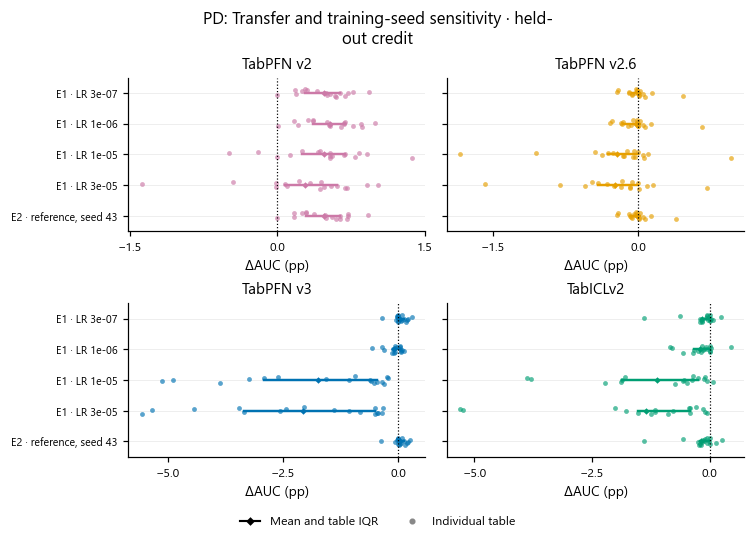

PD. Transfer and training-seed sensitivity · held-out credit. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabICLv2,roc_auc,17,0.797067,0.785886,-0.011181,...,-0.018589,-0.002421,-0.038751,0.000624,0,2,15,8,85,0.000000
1,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2,roc_auc,17,0.778915,0.783646,0.004731,...,0.002571,0.006950,-0.004872,0.013721,14,1,2,67,85,0.823529
2,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2.6,roc_auc,17,0.792242,0.790086,-0.002155,...,-0.003128,-0.000013,-0.018340,0.009577,1,7,9,24,85,0.058824
3,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v3,roc_auc,17,0.798170,0.780786,-0.017384,...,-0.029074,-0.004695,-0.051384,-0.002197,0,0,17,2,85,0.000000
4,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabICLv2,roc_auc,17,0.797067,0.795042,-0.002025,...,-0.003281,-0.000053,-0.008547,0.004457,1,6,10,20,85,0.058824
5,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2,roc_auc,17,0.778915,0.784332,0.005417,...,0.003624,0.006907,0.000125,0.009915,16,1,0,79,85,0.941176
6,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2.6,roc_auc,17,0.792242,0.792016,-0.000225,...,-0.001505,0.000243,-0.002939,0.006555,2,9,6,29,85,0.117647
7,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v3,roc_auc,17,0.798170,0.797360,-0.000810,...,-0.001181,0.000420,-0.005767,0.001205,1,11,5,36,85,0.058824
8,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabICLv2,roc_auc,17,0.797067,0.783573,-0.013494,...,-0.015273,-0.004130,-0.052942,-0.000623,0,1,16,8,85,0.000000
9,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabPFN v2,roc_auc,17,0.778915,0.781716,0.002801,...,0.000787,0.006054,-0.013776,0.010251,12,3,2,65,85,0.705882


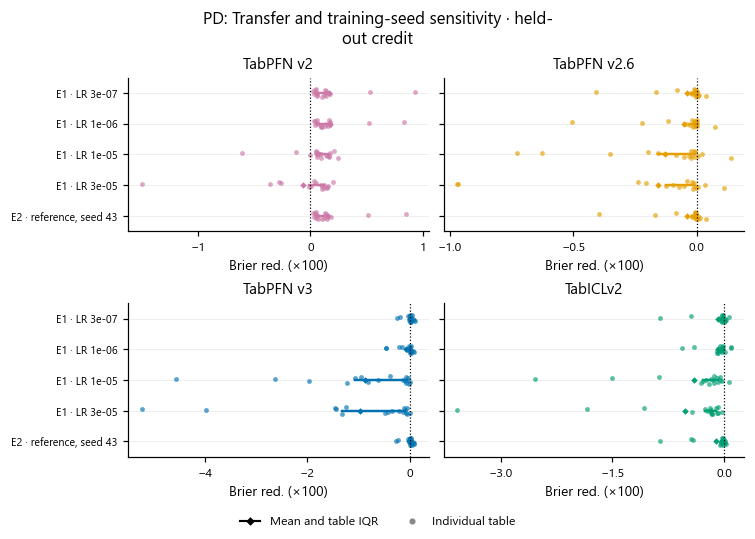

PD. Transfer and training-seed sensitivity · held-out credit. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabICLv2,brier_score,17,0.112620,0.116618,-0.003998,...,-0.002878,-0.000768,-0.025393,0.000631,1,0,16,8,85,0.058824
1,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2,brier_score,17,0.118123,0.117543,0.000581,...,0.000495,0.001666,-0.006073,0.002417,14,1,2,66,85,0.823529
2,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2.6,brier_score,17,0.113695,0.114959,-0.001264,...,-0.001561,-0.000074,-0.007273,0.001384,2,3,12,22,85,0.117647
3,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v3,brier_score,17,0.111856,0.120519,-0.008663,...,-0.010698,-0.000716,-0.045623,-0.000036,0,1,16,1,85,0.000000
4,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabICLv2,brier_score,17,0.112620,0.113414,-0.000794,...,-0.000769,-0.000164,-0.005585,0.000892,3,0,14,13,85,0.176471
5,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2,brier_score,17,0.118123,0.116422,0.001701,...,0.000584,0.001684,0.000334,0.008367,17,0,0,81,85,1.000000
6,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2.6,brier_score,17,0.113695,0.114222,-0.000527,...,-0.000259,-0.000002,-0.005038,0.000741,1,9,7,20,85,0.058824
7,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v3,brier_score,17,0.111856,0.112536,-0.000680,...,-0.000498,0.000170,-0.004671,0.000824,6,3,8,39,85,0.352941
8,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabICLv2,brier_score,17,0.112620,0.117844,-0.005225,...,-0.002610,-0.001057,-0.035842,-0.000318,0,0,17,8,85,0.000000
9,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabPFN v2,brier_score,17,0.118123,0.118781,-0.000657,...,-0.000146,0.001221,-0.015005,0.002048,11,1,5,60,85,0.647059


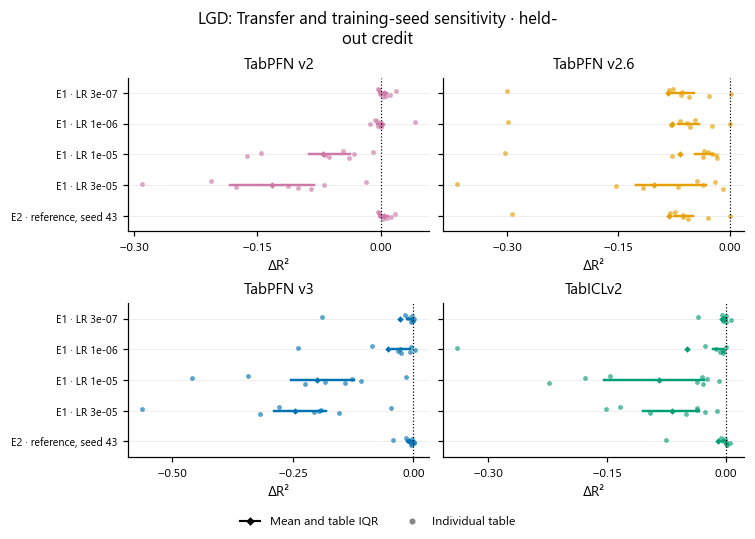

LGD. Transfer and training-seed sensitivity · held-out credit. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabICLv2,r2,8,0.531911,0.447357,-0.084554,...,-0.154433,-0.027517,-0.223336,-0.009379,0,0,8,1,40,0.000
1,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2,r2,8,0.474518,0.404168,-0.070350,...,-0.086656,-0.036785,-0.162064,-0.009382,0,0,8,3,40,0.000
2,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2.6,r2,8,0.539808,0.472585,-0.067223,...,-0.046242,-0.022424,-0.302679,-0.017069,0,0,8,2,40,0.000
3,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v3,r2,8,0.539412,0.339140,-0.200272,...,-0.253768,-0.123144,-0.457679,-0.015534,0,0,8,1,40,0.000
4,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabICLv2,r2,8,0.531911,0.482165,-0.049746,...,-0.015836,-0.004087,-0.339319,-0.000306,0,1,7,7,40,0.000
5,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2,r2,8,0.474518,0.476168,0.001650,...,-0.004904,-0.000612,-0.012546,0.042106,1,1,6,10,40,0.125
6,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2.6,r2,8,0.539808,0.461791,-0.078017,...,-0.069882,-0.040778,-0.297707,0.000287,0,1,7,4,40,0.000
7,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v3,r2,8,0.539412,0.487617,-0.051795,...,-0.044448,-0.005907,-0.239886,0.004118,1,0,7,6,40,0.125
8,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabICLv2,r2,8,0.531911,0.464230,-0.067681,...,-0.105017,-0.033658,-0.151006,-0.011801,0,0,8,2,40,0.000
9,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabPFN v2,r2,8,0.474518,0.342615,-0.131902,...,-0.183066,-0.080830,-0.290506,-0.017307,0,0,8,0,40,0.000


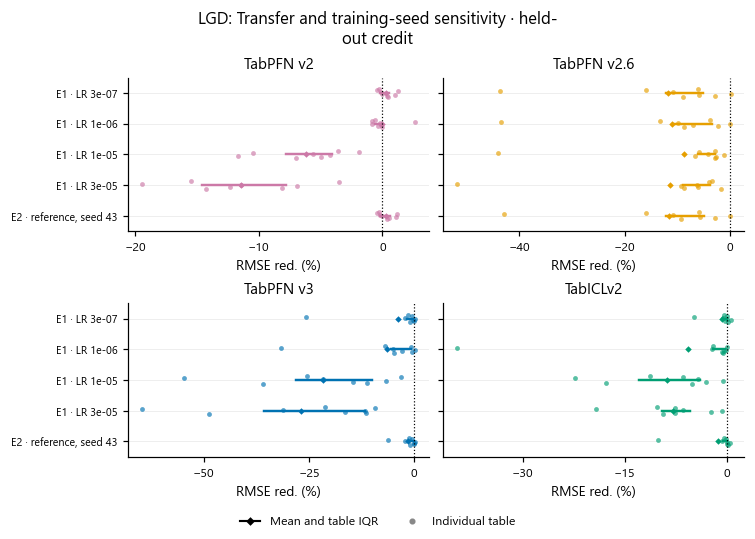

LGD. Transfer and training-seed sensitivity · held-out credit. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabICLv2,rmse,8,0.224874,0.246127,-0.088716,...,-0.129107,-0.039600,-0.223104,-0.005980,0,0,8,1,40,0.000
1,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2,rmse,8,0.240824,0.256576,-0.061851,...,-0.078321,-0.040630,-0.117233,-0.019274,0,0,8,3,40,0.000
2,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2.6,rmse,8,0.221788,0.240889,-0.088026,...,-0.060765,-0.028067,-0.440549,-0.011426,0,0,8,2,40,0.000
3,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v3,rmse,8,0.222704,0.269034,-0.216783,...,-0.281159,-0.100143,-0.547461,-0.032467,0,0,8,1,40,0.000
4,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabICLv2,rmse,8,0.224874,0.238889,-0.057612,...,-0.021508,-0.003813,-0.396020,-0.000636,0,1,7,7,40,0.000
5,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2,rmse,8,0.240824,0.240338,-0.000367,...,-0.006382,-0.000703,-0.008573,0.026602,1,2,5,10,40,0.125
6,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2.6,rmse,8,0.221788,0.243621,-0.110800,...,-0.107512,-0.034329,-0.434378,0.000090,0,1,7,4,40,0.000
7,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v3,rmse,8,0.222704,0.237118,-0.065351,...,-0.055750,-0.007487,-0.315545,0.002545,1,0,7,6,40,0.125
8,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabICLv2,rmse,8,0.224874,0.242025,-0.079732,...,-0.095917,-0.054547,-0.192603,-0.007525,0,0,8,2,40,0.000
9,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabPFN v2,rmse,8,0.240824,0.269318,-0.114508,...,-0.145843,-0.078276,-0.194763,-0.034926,0,0,8,0,40,0.000


In [3]:
for track in studies:
    for metric in (sy.PRIMARY[track], sy.SECONDARY[track]):
        data = catalogs[track]['credit', metric]
        cp.show(sink, rq.plot_effects(data, track, title=rq.TITLES[QUESTION] + ' · held-out credit', name='credit_' + metric), track=track)
        report.table(track.upper() + ' original/CPT scores and paired effects: ' + metric, sy.summarize(data))
report.add('2. Original-to-CPT effects across the research question', 'Different experiments are shown in one view for each metric. Every dot is a table, the diamond is the equal-table mean and the segment is the table IQR. The same tables contribute to every available arm within each model. This is heterogeneity, not a confidence interval.')

## 3. What changes when a specific choice changes?

Paired contrasts compare the same table and model. A positive contrast can mean less damage, not positive transfer. E2 compares training seeds 42 and 43 at the predefined reference recipe, on the same tables and evaluation folds.

,base,dataset,metric,domain,effect_reference,effect_alternative,effect,config
0,TabICLv2,Bondora Peer-to-Peer,roc_auc,credit,-0.000682,-0.000701,-0.000019,E2 seed 43 − seed 42
1,TabICLv2,Cobranded,roc_auc,credit,0.000016,-0.000027,-0.000044,E2 seed 43 − seed 42
2,TabICLv2,Credit Risk,roc_auc,credit,-0.006251,-0.005789,0.000462,E2 seed 43 − seed 42
3,TabICLv2,GMSC,roc_auc,credit,-0.000584,-0.000946,-0.000362,E2 seed 43 − seed 42
4,TabICLv2,German Credit,roc_auc,credit,0.002416,0.002673,0.000258,E2 seed 43 − seed 42
...,...,...,...,...,...,...,...,...
63,TabPFN v3,PropPD2,roc_auc,credit,0.001837,0.001839,0.000001,E2 seed 43 − seed 42
64,TabPFN v3,SBA Loans Case,roc_auc,credit,0.000535,0.000432,-0.000103,E2 seed 43 − seed 42
65,TabPFN v3,Taiwan Credit Card,roc_auc,credit,0.000071,0.000077,0.000005,E2 seed 43 − seed 42
66,TabPFN v3,Thomas,roc_auc,credit,0.001645,0.001597,-0.000048,E2 seed 43 − seed 42


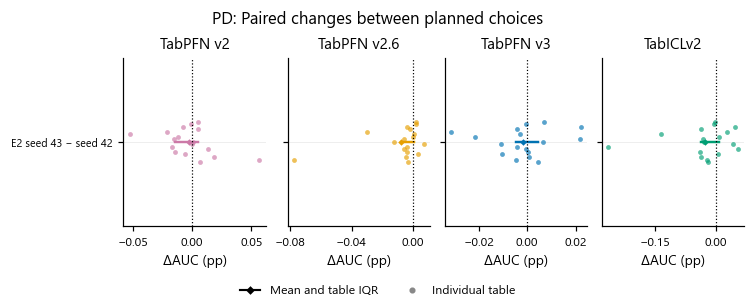

PD. Paired changes between planned choices. Paired differences between the named choices' CPT effects, on identical tables. Positive favors the alternative choice and can mean less degradation, rather than positive transfer. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Both choices' effects and their named-table differences are retained in the text summary.

,base,dataset,metric,domain,effect_reference,effect_alternative,effect,config
0,TabICLv2,Bondora Peer-to-Peer,brier_score,credit,-0.000232,-2.684087e-04,-0.000037,E2 seed 43 − seed 42
1,TabICLv2,Cobranded,brier_score,credit,-0.000162,-1.178811e-04,0.000044,E2 seed 43 − seed 42
2,TabICLv2,Credit Risk,brier_score,credit,-0.004416,-4.491229e-03,-0.000075,E2 seed 43 − seed 42
3,TabICLv2,GMSC,brier_score,credit,-0.000076,-1.695688e-04,-0.000094,E2 seed 43 − seed 42
4,TabICLv2,German Credit,brier_score,credit,0.000640,-1.831824e-07,-0.000641,E2 seed 43 − seed 42
...,...,...,...,...,...,...,...,...
63,TabPFN v3,PropPD2,brier_score,credit,0.000144,1.353232e-04,-0.000008,E2 seed 43 − seed 42
64,TabPFN v3,SBA Loans Case,brier_score,credit,0.001013,8.971817e-04,-0.000116,E2 seed 43 − seed 42
65,TabPFN v3,Taiwan Credit Card,brier_score,credit,0.000218,2.206665e-04,0.000003,E2 seed 43 − seed 42
66,TabPFN v3,Thomas,brier_score,credit,0.000300,3.287634e-04,0.000029,E2 seed 43 − seed 42


,base,dataset,metric,domain,effect_reference,effect_alternative,effect,config
0,TabICLv2,Freddie Mac,r2,credit,-0.005712,-0.006337,-6.244659e-04,E2 seed 43 − seed 42
1,TabICLv2,LendingClub (LGD),r2,credit,-0.000299,-0.000680,-3.814697e-04,E2 seed 43 − seed 42
2,TabICLv2,PropLGD1,r2,credit,-0.035748,-0.075833,-4.008436e-02,E2 seed 43 − seed 42
3,TabICLv2,PropLGD2,r2,credit,-0.003092,-0.004322,-1.230490e-03,E2 seed 43 − seed 42
4,TabICLv2,PropLGD3,r2,credit,-0.001415,-0.000310,1.105571e-03,E2 seed 43 − seed 42
5,TabICLv2,PropLGD4,r2,credit,0.005838,0.005129,-7.085800e-04,E2 seed 43 − seed 42
6,TabICLv2,PropLGD5,r2,credit,-0.003457,-0.000177,3.280187e-03,E2 seed 43 − seed 42
7,TabICLv2,SBA Loans Case (LGD),r2,credit,0.000006,0.000619,6.123066e-04,E2 seed 43 − seed 42
8,TabPFN v2,Freddie Mac,r2,credit,-0.003251,-0.003384,-1.327276e-04,E2 seed 43 − seed 42
9,TabPFN v2,LendingClub (LGD),r2,credit,-0.002143,-0.002135,8.308887e-06,E2 seed 43 − seed 42


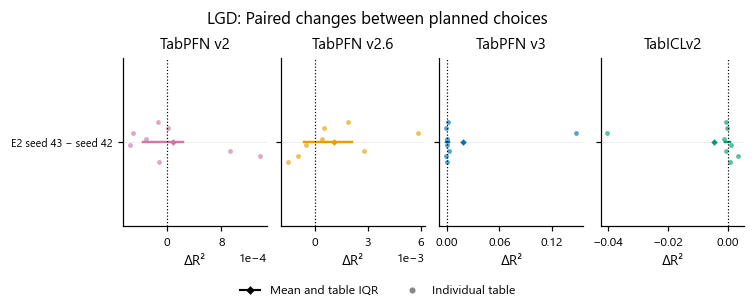

LGD. Paired changes between planned choices. Paired differences between the named choices' CPT effects, on identical tables. Positive favors the alternative choice and can mean less degradation, rather than positive transfer. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Both choices' effects and their named-table differences are retained in the text summary.

,base,dataset,metric,domain,effect_reference,effect_alternative,effect,config
0,TabICLv2,Freddie Mac,rmse,credit,-0.004643,-0.005146,-0.000503,E2 seed 43 − seed 42
1,TabICLv2,LendingClub (LGD),rmse,credit,-0.000580,-0.001444,-0.000864,E2 seed 43 − seed 42
2,TabICLv2,PropLGD1,rmse,credit,-0.048784,-0.100918,-0.052133,E2 seed 43 − seed 42
3,TabICLv2,PropLGD2,rmse,credit,-0.005905,-0.007933,-0.002028,E2 seed 43 − seed 42
4,TabICLv2,PropLGD3,rmse,credit,-0.000878,-0.000201,0.000678,E2 seed 43 − seed 42
5,TabICLv2,PropLGD4,rmse,credit,0.005110,0.004064,-0.001047,E2 seed 43 − seed 42
6,TabICLv2,PropLGD5,rmse,credit,-0.003215,0.000161,0.003376,E2 seed 43 − seed 42
7,TabICLv2,SBA Loans Case (LGD),rmse,credit,0.000683,0.001433,0.000750,E2 seed 43 − seed 42
8,TabPFN v2,Freddie Mac,rmse,credit,-0.002650,-0.002756,-0.000106,E2 seed 43 − seed 42
9,TabPFN v2,LendingClub (LGD),rmse,credit,-0.004391,-0.004376,0.000015,E2 seed 43 − seed 42


In [4]:
for track in studies:
    for metric in (sy.PRIMARY[track], sy.SECONDARY[track]):
        differences = rq.choice_differences(catalogs[track]['credit', metric], QUESTION)
        report.table(track.upper() + ' matched choice differences: ' + metric, differences)
        if metric == sy.PRIMARY[track]:
            cp.show(sink, rq.plot_effects(differences, track, title='Paired changes between planned choices', name='choices_' + metric, contrast=True), track=track)
report.add('3. What changes when a specific choice changes?', 'Paired contrasts compare the same table and model. A positive contrast can mean less damage, not positive transfer. E2 compares training seeds 42 and 43 at the predefined reference recipe, on the same tables and evaluation folds.')

## 4. Non-credit retention alongside transfer

The four same-task non-credit tables are a bounded retention panel. Their four training-partition results are averaged within table before equal-table summaries. Original/CPT comparisons remain paired within each recipe and precision policy.

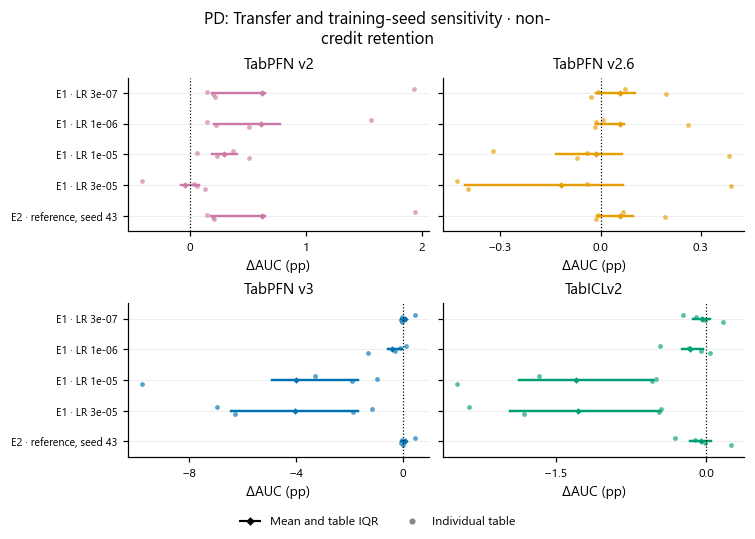

PD. Transfer and training-seed sensitivity · non-credit retention. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabICLv2,roc_auc,4,0.874683,0.861723,-0.012960,...,-0.018714,-0.005255,-0.024843,-0.004978,0,0,4,9,80,0.00
1,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2,roc_auc,4,0.848628,0.851576,0.002949,...,0.001896,0.004096,0.000579,0.005130,3,1,0,49,80,0.75
2,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2.6,roc_auc,4,0.871975,0.871847,-0.000128,...,-0.001340,0.000652,-0.003220,0.003829,1,2,1,34,80,0.25
3,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v3,roc_auc,4,0.872980,0.833168,-0.039812,...,-0.048999,-0.016709,-0.097652,-0.009806,0,0,4,1,80,0.00
4,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabICLv2,roc_auc,4,0.874683,0.873079,-0.001603,...,-0.002415,-0.000291,-0.004610,0.000401,0,2,2,27,80,0.00
5,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2,roc_auc,4,0.848628,0.854741,0.006114,...,0.002050,0.007744,0.001482,0.015610,4,0,0,71,80,1.00
6,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2.6,roc_auc,4,0.871975,0.872571,0.000596,...,-0.000149,0.000701,-0.000150,0.002621,1,3,0,47,80,0.25
7,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v3,roc_auc,4,0.872980,0.869044,-0.003936,...,-0.005543,-0.000399,-0.013097,0.001366,1,1,2,26,80,0.25
8,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabICLv2,roc_auc,4,0.874683,0.861945,-0.012738,...,-0.019533,-0.004630,-0.023624,-0.004477,0,0,4,13,80,0.00
9,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabPFN v2,roc_auc,4,0.848628,0.848177,-0.000451,...,-0.000753,0.000813,-0.004151,0.001330,1,2,1,42,80,0.25


,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabICLv2,brier_score,4,0.062617,0.066330,-0.003713,...,-0.004715,-0.002181,-0.006554,-0.001933,0,0,4,6,80,0.00
1,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2,brier_score,4,0.066848,0.066062,0.000786,...,0.000314,0.001245,0.000064,0.001535,3,1,0,62,80,0.75
2,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2.6,brier_score,4,0.064141,0.063522,0.000619,...,-0.000107,0.000677,-0.000129,0.002706,1,1,2,37,80,0.25
3,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v3,brier_score,4,0.062912,0.071948,-0.009036,...,-0.012125,-0.004523,-0.017522,-0.003396,0,0,4,0,80,0.00
4,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabICLv2,brier_score,4,0.062617,0.063453,-0.000835,...,-0.001527,-0.000241,-0.001592,0.000117,1,0,3,22,80,0.25
5,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2,brier_score,4,0.066848,0.065603,0.001245,...,0.000587,0.001689,0.000365,0.002551,4,0,0,72,80,1.00
6,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2.6,brier_score,4,0.064141,0.063553,0.000589,...,-0.000027,0.000720,-0.000104,0.002251,2,1,1,46,80,0.50
7,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v3,brier_score,4,0.062912,0.064099,-0.001187,...,-0.001413,-0.000370,-0.003491,-0.000065,0,1,3,14,80,0.00
8,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabICLv2,brier_score,4,0.062617,0.066183,-0.003566,...,-0.004955,-0.002008,-0.005635,-0.001834,0,0,4,5,80,0.00
9,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabPFN v2,brier_score,4,0.066848,0.066713,0.000134,...,-0.000233,0.000455,-0.000524,0.000887,2,0,2,53,80,0.50


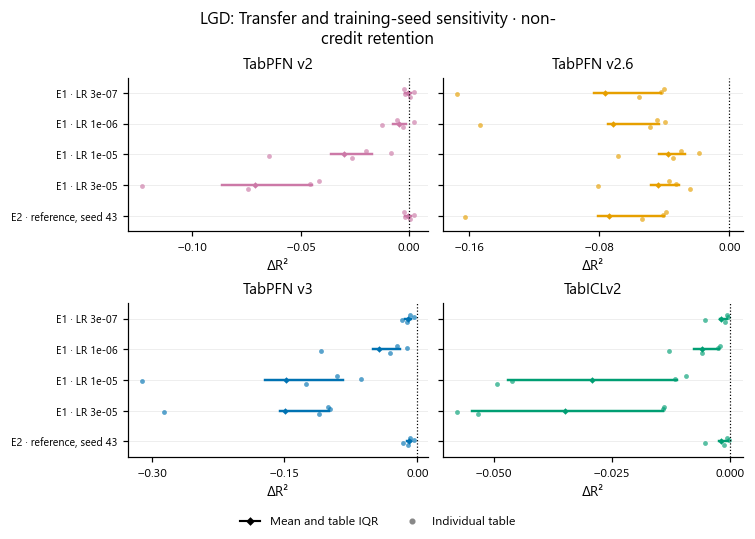

LGD. Transfer and training-seed sensitivity · non-credit retention. Each CPT recipe is compared with its own original model; positive values favor CPT. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. Each model uses the same table cohort across all displayed arms; models can have different cohorts. Dots are individual tables, diamonds equal-table means and segments table interquartile ranges, not confidence intervals. Axes retain all finite values and can differ between models. Missing recipes are reported in coverage, not assigned zero. Original scores, adapted scores and named-table effects are retained in the text summary.

,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabICLv2,r2,4,0.904621,0.875469,-0.029152,...,-0.046982,-0.011097,-0.049384,-0.009369,0,0,4,0,80,0.00
1,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2,r2,4,0.876377,0.846509,-0.029868,...,-0.035969,-0.017016,-0.064726,-0.008511,0,0,4,4,80,0.00
2,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2.6,r2,4,0.900482,0.862537,-0.037946,...,-0.043253,-0.027195,-0.068302,-0.018475,0,0,4,0,80,0.00
3,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v3,r2,4,0.908113,0.760119,-0.147994,...,-0.172224,-0.084178,-0.311130,-0.064028,0,0,4,0,80,0.00
4,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabICLv2,r2,4,0.904621,0.898817,-0.005804,...,-0.007654,-0.002364,-0.012790,-0.001998,0,0,4,9,80,0.00
5,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2,r2,4,0.876377,0.871649,-0.004727,...,-0.007468,-0.001468,-0.012623,0.002129,1,0,3,15,80,0.25
6,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2.6,r2,4,0.900482,0.828850,-0.071632,...,-0.074958,-0.043179,-0.153728,-0.039793,0,0,4,0,80,0.00
7,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v3,r2,4,0.908113,0.864790,-0.043323,...,-0.050015,-0.020005,-0.108523,-0.011373,0,0,4,0,80,0.00
8,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabICLv2,r2,4,0.904621,0.869807,-0.034814,...,-0.054521,-0.014060,-0.057856,-0.013864,0,0,4,1,80,0.00
9,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabPFN v2,r2,4,0.876377,0.805297,-0.071080,...,-0.086360,-0.044520,-0.123259,-0.041461,0,0,4,0,80,0.00


,experiment,study,approach,config,base,metric,tables,original,adapted,mean,...,q25,q75,minimum,maximum,improved,negligible,worse,folds_improved,folds,share_improved
0,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabICLv2,rmse,4,4.209030,5.060649,-0.162920,...,-0.194564,-0.106959,-0.283456,-0.091018,0,0,4,0,80,0.00
1,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2,rmse,4,4.617752,5.221368,-0.152209,...,-0.182901,-0.090426,-0.289140,-0.077463,0,0,4,4,80,0.00
2,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v2.6,rmse,4,4.307522,5.181454,-0.241017,...,-0.271388,-0.161955,-0.448336,-0.131082,0,0,4,0,80,0.00
3,1,Main grid,Full CPT,Grid all · LR 1e-05 · λ 0.003,TabPFN v3,rmse,4,4.182164,6.857226,-0.761072,...,-0.828035,-0.529609,-1.332525,-0.518615,0,0,4,0,80,0.00
4,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabICLv2,rmse,4,4.209030,4.356920,-0.033448,...,-0.039580,-0.026673,-0.042002,-0.026182,0,0,4,9,80,0.00
5,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2,rmse,4,4.617752,4.682745,-0.027233,...,-0.037425,-0.007441,-0.091969,0.018306,1,0,3,15,80,0.25
6,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v2.6,rmse,4,4.307522,5.679893,-0.382844,...,-0.409823,-0.288173,-0.624645,-0.276426,0,0,4,0,80,0.00
7,1,Main grid,Full CPT,Grid all · LR 1e-06 · λ 0.003,TabPFN v3,rmse,4,4.182164,4.974862,-0.238816,...,-0.265296,-0.171737,-0.451292,-0.107537,0,0,4,0,80,0.00
8,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabICLv2,rmse,4,4.209030,5.180033,-0.197691,...,-0.251733,-0.129352,-0.312465,-0.111512,0,0,4,1,80,0.00
9,1,Main grid,Full CPT,Grid all · LR 3e-05 · λ 0.003,TabPFN v2,rmse,4,4.617752,6.184851,-0.359238,...,-0.415450,-0.306175,-0.538967,-0.173214,0,0,4,0,80,0.00


In [5]:
for track, values in studies.items():
    primary = catalogs[track]['credit', sy.PRIMARY[track]]
    retention = catalogs[track]['ood', sy.PRIMARY[track]]
    cp.show(sink, rq.plot_effects(retention, track, title=rq.TITLES[QUESTION] + ' · non-credit retention', name='retention_' + sy.PRIMARY[track], min_arms=2 if QUESTION == 2 else 1), track=track)
    for metric in (sy.PRIMARY[track], sy.SECONDARY[track]):
        report.table(track.upper() + ' non-credit absolute scores and effects: ' + metric, sy.summarize(catalogs[track]['ood', metric]))
report.add('4. Non-credit retention alongside transfer', 'The four same-task non-credit tables are a bounded retention panel. Their four training-partition results are averaged within table before equal-table summaries. Original/CPT comparisons remain paired within each recipe and precision policy.')

## 5. The fixed reference: named tables and prediction quality

The reference is fixed independently of held-out outcomes. Named-table plots and saved-prediction diagnostics show whether the mean hides heterogeneity. Signed residuals are not the theoretical model bias; table-bootstrap intervals are conditional on these fitted checkpoints.

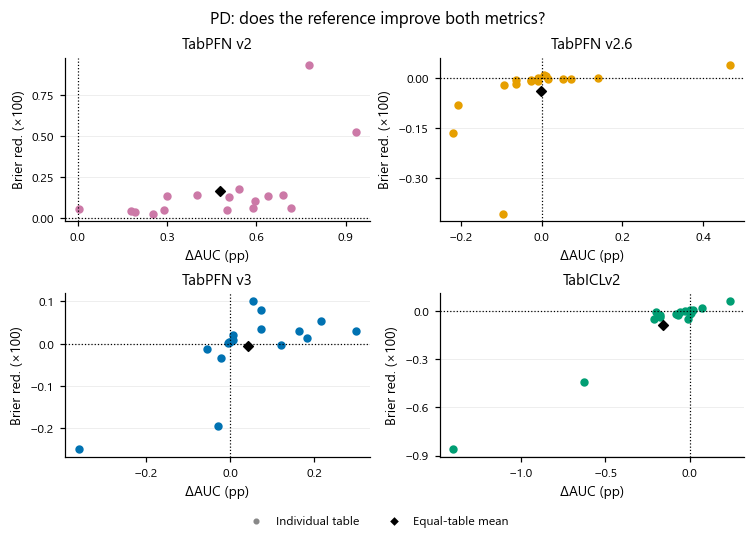

PD. The predefined full-update reference (peak LR 3e-7, L2-SP 0.003, seed 42) on held-out credit tables. Horizontal values are ΔAUC (percentage points); vertical values are Brier reduction (×100). Each colored point represents one table with five complete paired outer folds for both metrics; the diamond is their equal-table mean. Both directions are oriented so that positive favors CPT. Axis ranges differ by base to retain small effects. AUC measures ranking; Brier score measures probability error, so their changes need not agree. 

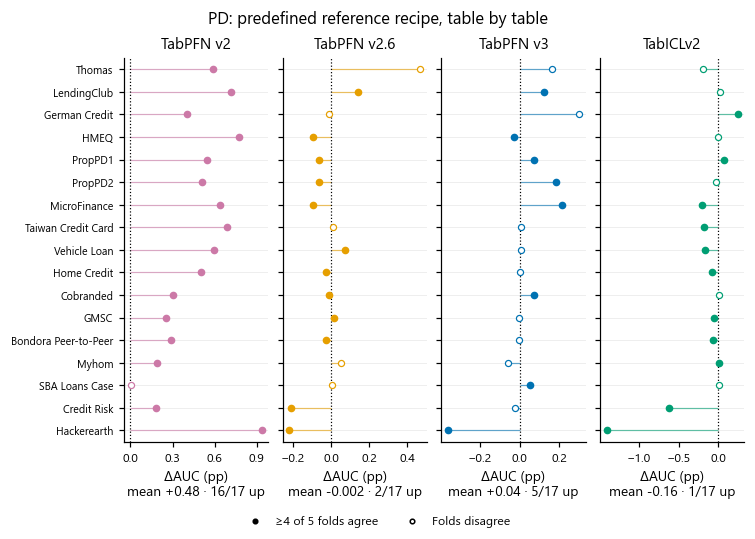

PD. Experiment 1, predefined reference recipe (all trainable weights updated, peak LR 3e-7, L2-SP λ 0.003, seed 42), final five-fold benchmark: paired change in AUC (percentage points) on every held-out credit table relative to the original model of the same base. Each axis label gives the equal-table mean and the number of tables improving by more than 0.1 pp. Filled markers: at least four of the five outer folds change in the direction of the table mean; open markers: the folds disagree. Tables are ordered by their mean effect across the four bases; horizontal axes differ between models. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. 

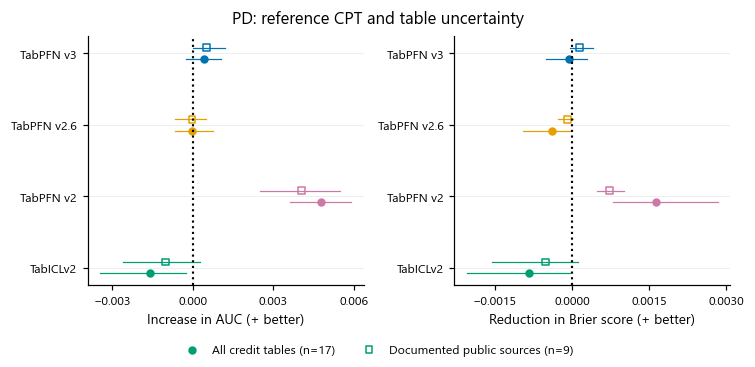

PD. Mean paired benchmark effects of the predefined full-update CPT reference and 95% conditional table-bootstrap intervals. Positive effects favor CPT; RMSE is reported as fractional error reduction. Filled circles include all credit tables; open squares retain documented public sources. Each table contributes the mean of five paired outer folds. Source restriction is based on provenance, not scores. Intervals do not capture training-seed uncertainty or establish source independence.

,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed,metric
0,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Bondora Peer-to-Peer,0.897219,0.896537,-0.000682,-0.000682,Bondora Peer-to-Peer,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.000682,42,roc_auc
1,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Cobranded,0.842712,0.842729,0.000016,0.000016,Cobranded,TabICLv2,3.000000e-07,False,0.003,one_sample,0.000016,42,roc_auc
2,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Credit Risk,0.955257,0.949006,-0.006251,-0.006251,Credit Risk,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.006251,42,roc_auc
3,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,GMSC,0.867210,0.866626,-0.000584,-0.000584,GMSC,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.000584,42,roc_auc
4,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,German Credit,0.790140,0.792556,0.002416,0.002416,German Credit,TabICLv2,3.000000e-07,False,0.003,one_sample,0.002416,42,roc_auc
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
403,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropPD2,0.229404,0.229532,0.000128,0.000128,PropPD2,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.000128,42,f1
404,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,SBA Loans Case,0.923122,0.929796,0.006675,0.006675,SBA Loans Case,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.006675,42,f1
405,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Taiwan Credit Card,0.548195,0.547957,-0.000238,-0.000238,Taiwan Credit Card,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.000238,42,f1
406,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Thomas,0.432436,0.442147,0.009711,0.009711,Thomas,TabPFN v3,3.000000e-07,False,0.003,one_sample,0.009711,42,f1


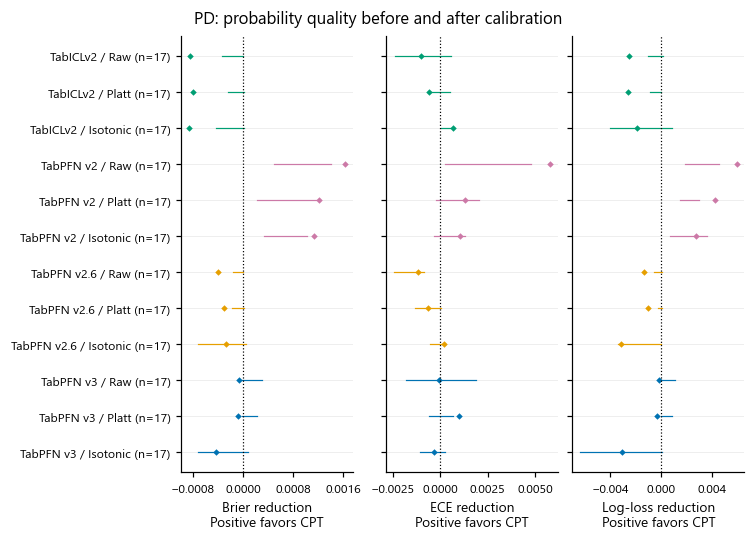

PD. Changes in the displayed outer-test probability-quality scores for the predefined full-update reference (LR 3e-7, L2-SP 0.003, one-sample training) relative to its untuned base. Positive reductions favor continued pretraining (CPT). Raw probabilities and validation-fitted Platt and isotonic calibration use a common dataset cohort within each base: all 9 scores require the same five completed, matched outer folds. Diamonds show equal-dataset means; horizontal lines span dataset quartiles, not confidence intervals. Log loss, when exported, is in nats; ECE depends on the binning scheme.

,base,dataset,partition,arm,status,reason
0,TabICLv2,Bondora Peer-to-Peer,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,HMEQ,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,MicroFinance,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,Thomas,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,GMSC,1,Reference CPT,verified,"Five folds; matched row identities, targets an..."
...,...,...,...,...,...,...
63,TabPFN v3,PropPD2,2,Reference CPT,verified,"Five folds; matched row identities, targets an..."
64,TabPFN v3,Cobranded,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."
65,TabPFN v3,Home Credit,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."
66,TabPFN v3,LendingClub,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,Bondora Peer-to-Peer,0,Reference CPT,730176,0.138105,0.132381,0.132018,-0.005724,-0.006087,-0.000363,0.080427,0.080659,-0.000232,-0.000363,0.015065,0.007980
1,TabICLv2,HMEQ,0,Reference CPT,5960,0.199497,0.190217,0.191989,-0.009280,-0.007508,0.001772,0.017732,0.018200,-0.000468,0.001772,0.034692,0.011271
2,TabICLv2,MicroFinance,0,Reference CPT,158700,0.378091,0.364455,0.364086,-0.013636,-0.014004,-0.000369,0.217943,0.218420,-0.000477,-0.000369,0.023827,0.018202
3,TabICLv2,Thomas,0,Reference CPT,1225,0.263673,0.247090,0.244012,-0.016584,-0.019662,-0.003078,0.183083,0.183146,-0.000063,-0.003078,0.014727,0.010257
4,TabICLv2,GMSC,1,Reference CPT,150000,0.066840,0.057780,0.056710,-0.009060,-0.010130,-0.001071,0.049082,0.049157,-0.000076,-0.001071,0.007099,0.003449
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
63,TabPFN v3,PropPD2,2,Reference CPT,105471,0.092755,0.075083,0.077348,-0.017673,-0.015407,0.002265,0.082365,0.082222,0.000144,0.002265,0.007568,0.005367
64,TabPFN v3,Cobranded,3,Reference CPT,80000,0.246213,0.234716,0.236553,-0.011496,-0.009659,0.001837,0.130932,0.130591,0.000341,0.001837,0.017345,0.009891
65,TabPFN v3,Home Credit,3,Reference CPT,307511,0.080729,0.066750,0.068345,-0.013979,-0.012384,0.001595,0.068395,0.068366,0.000030,0.001595,0.009478,0.005742
66,TabPFN v3,LendingClub,3,Reference CPT,9578,0.160054,0.140981,0.138785,-0.019073,-0.021269,-0.002196,0.126388,0.126412,-0.000024,-0.002196,0.011739,0.008609


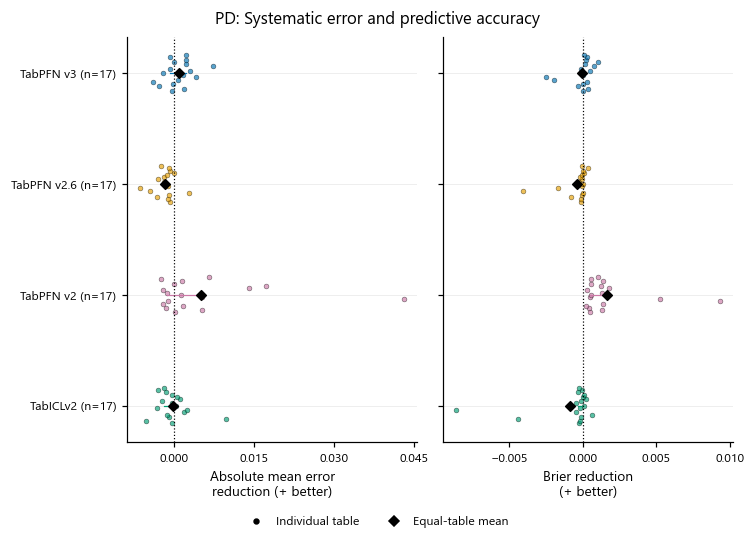

PD. Matched five-fold out-of-fold predictions on held-out credit tables. Circles show individual tables; their small vertical offsets follow table-name order and have no quantitative meaning. Black diamonds are equal-table means; segments are dataset interquartile ranges, not confidence intervals. Each label gives the number of tables. Mean error is predicted minus observed target, pooled over test rows within a table. The left panel measures reduction of its absolute value; the right measures reduction in squared error. These are empirical errors, not a theoretical bias–variance decomposition.

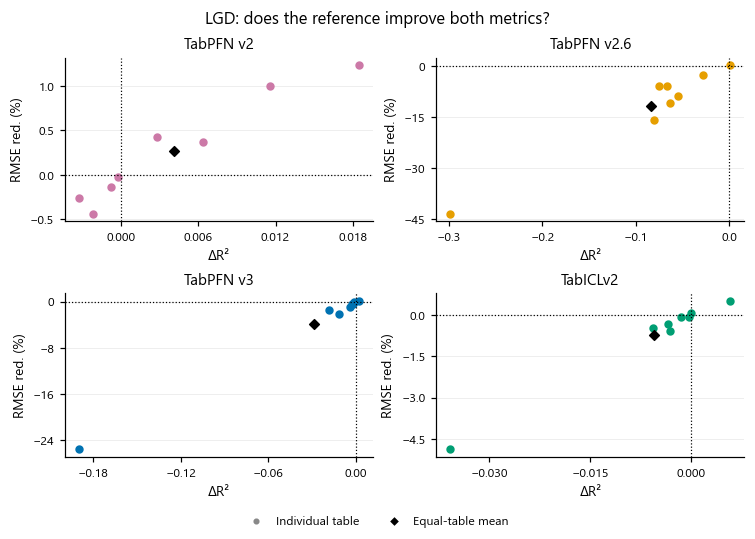

LGD. The predefined full-update reference (peak LR 3e-7, L2-SP 0.003, seed 42) on held-out credit tables. Horizontal values are ΔR²; vertical values are RMSE reduction (%). Each colored point represents one table with five complete paired outer folds for both metrics; the diamond is their equal-table mean. Both directions are oriented so that positive favors CPT. Axis ranges differ by base to retain small effects. R² and RMSE derive from squared error and are not independent confirmations; relative RMSE puts the size of error changes in context. 

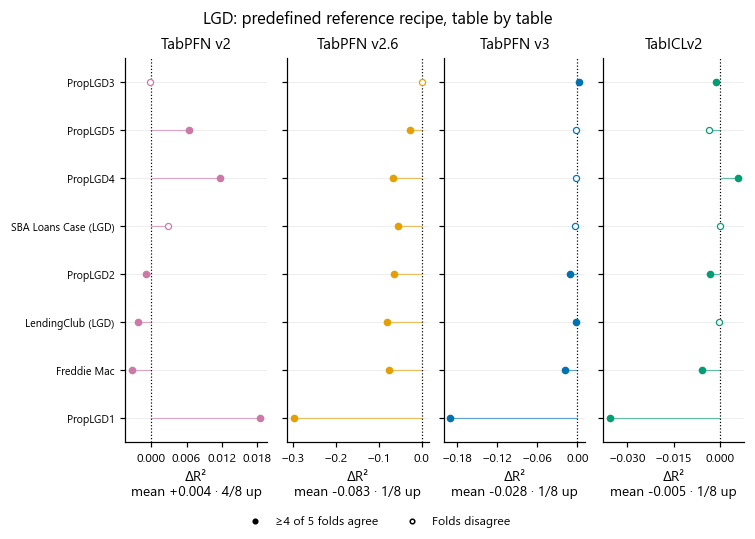

LGD. Experiment 1, predefined reference recipe (all trainable weights updated, peak LR 3e-7, L2-SP λ 0.003, seed 42), final five-fold benchmark: paired change in R² on every held-out credit table relative to the original model of the same base. Each axis label gives the equal-table mean and the number of tables improving by more than 0.001 R². Filled markers: at least four of the five outer folds change in the direction of the table mean; open markers: the folds disagree. Tables are ordered by their mean effect across the four bases; horizontal axes differ between models. Each adapted model is paired with its own original checkpoint on the same split and outer fold; five folds are averaged within table and tables receive equal weight. 

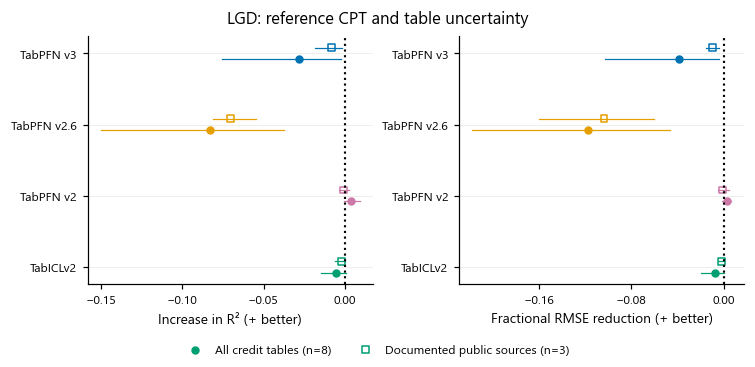

LGD. Mean paired benchmark effects of the predefined full-update CPT reference and 95% conditional table-bootstrap intervals. Positive effects favor CPT; RMSE is reported as fractional error reduction. Filled circles include all credit tables; open squares retain documented public sources. Each table contributes the mean of five paired outer folds. Source restriction is based on provenance, not scores. Intervals do not capture training-seed uncertainty or establish source independence.

,method_dirname,base_short,test_dataset_id,untuned,trained,delta,absolute_delta,dataset,base,learning_rate,frozen,l2sp_lambda,sampling,effect,seed,metric
0,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,Freddie Mac,0.383912,0.378199,-0.005712,-0.005712,Freddie Mac,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.005712,42,r2
1,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,LendingClub (LGD),0.763625,0.763326,-0.000299,-0.000299,LendingClub (LGD),TabICLv2,3.000000e-07,False,0.003,one_sample,-0.000299,42,r2
2,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,PropLGD1,0.642400,0.606651,-0.035748,-0.035748,PropLGD1,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.035748,42,r2
3,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,PropLGD2,0.727264,0.724172,-0.003092,-0.003092,PropLGD2,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.003092,42,r2
4,tabicl-trained__tabicl-v2__lr3e-07__l2sp0.003,TabICLv2,PropLGD3,0.212188,0.210773,-0.001415,-0.001415,PropLGD3,TabICLv2,3.000000e-07,False,0.003,one_sample,-0.001415,42,r2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
91,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD2,0.096023,0.102354,-0.006330,-0.006330,PropLGD2,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.006330,42,mae
92,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD3,0.213285,0.219817,-0.006531,-0.006531,PropLGD3,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.006531,42,mae
93,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD4,0.205333,0.218105,-0.012772,-0.012772,PropLGD4,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.012772,42,mae
94,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD5,0.227024,0.238461,-0.011437,-0.011437,PropLGD5,TabPFN v3,3.000000e-07,False,0.003,one_sample,-0.011437,42,mae


,base,dataset,partition,arm,status,reason
0,TabICLv2,PropLGD2,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
1,TabICLv2,PropLGD3,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
2,TabICLv2,Freddie Mac,1,Reference CPT,verified,"Five folds; matched row identities, targets an..."
3,TabICLv2,PropLGD1,1,Reference CPT,verified,"Five folds; matched row identities, targets an..."
4,TabICLv2,LendingClub (LGD),2,Reference CPT,verified,"Five folds; matched row identities, targets an..."
5,TabICLv2,PropLGD5,2,Reference CPT,verified,"Five folds; matched row identities, targets an..."
6,TabICLv2,PropLGD4,3,Reference CPT,verified,"Five folds; matched row identities, targets an..."
7,TabICLv2,SBA Loans Case (LGD),3,Reference CPT,verified,"Five folds; matched row identities, targets an..."
8,TabPFN v2,PropLGD2,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."
9,TabPFN v2,PropLGD3,0,Reference CPT,verified,"Five folds; matched row identities, targets an..."


,base,dataset,partition,arm,test_rows,target_mean,original_mean,adapted_mean,original_mean_error,adapted_mean_error,absolute_mean_error_improvement,original_mse,adapted_mse,mse_improvement,prediction_shift,prediction_rms_change,prediction_mean_absolute_change
0,TabICLv2,PropLGD2,0,Reference CPT,4637,0.392032,0.389712,0.393213,-0.002320,0.001181,0.001139,0.020063,0.020293,-0.000230,0.003501,0.019502,0.012959
1,TabICLv2,PropLGD3,0,Reference CPT,2545,0.228130,0.233124,0.231460,0.004994,0.003330,0.001664,0.085241,0.085390,-0.000149,-0.001664,0.006967,0.005461
2,TabICLv2,Freddie Mac,1,Reference CPT,16002,0.458843,0.461581,0.459349,0.002739,0.000506,0.002233,0.062385,0.062963,-0.000578,-0.002233,0.032142,0.023928
3,TabICLv2,PropLGD1,1,Reference CPT,57932,0.704420,0.695587,0.665935,-0.008833,-0.038485,-0.029652,0.062182,0.068399,-0.006217,-0.029652,0.069325,0.042433
4,TabICLv2,LendingClub (LGD),2,Reference CPT,5627,0.590511,0.591696,0.595164,0.001185,0.004654,-0.003468,0.015733,0.015753,-0.000020,0.003468,0.005307,0.004142
5,TabICLv2,PropLGD5,2,Reference CPT,594,0.330075,0.327944,0.331615,-0.002131,0.001540,0.000591,0.104725,0.105327,-0.000602,0.003670,0.028141,0.021361
6,TabICLv2,PropLGD4,3,Reference CPT,762,0.323387,0.323913,0.318712,0.000526,-0.004676,-0.004150,0.082863,0.082027,0.000835,-0.005201,0.031538,0.022870
7,TabICLv2,SBA Loans Case (LGD),3,Reference CPT,686,0.628030,0.630627,0.626888,0.002597,-0.001142,0.001455,0.017411,0.017391,0.000020,-0.003738,0.014194,0.009805
8,TabPFN v2,PropLGD2,0,Reference CPT,4637,0.392032,0.394717,0.398286,0.002684,0.006254,-0.003569,0.020880,0.020936,-0.000057,0.003569,0.015649,0.010940
9,TabPFN v2,PropLGD3,0,Reference CPT,2545,0.228130,0.236428,0.259312,0.008297,0.031182,-0.022885,0.085179,0.085182,-0.000003,0.022885,0.029096,0.025852


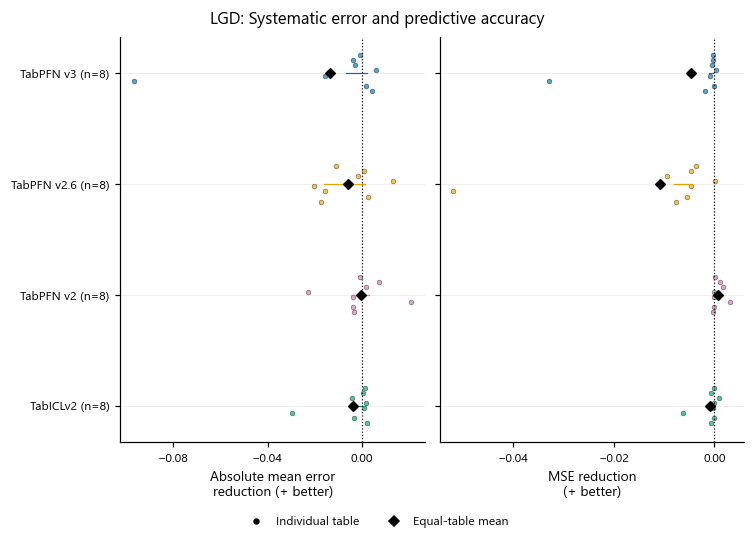

LGD. Matched five-fold out-of-fold predictions on held-out credit tables. Circles show individual tables; their small vertical offsets follow table-name order and have no quantitative meaning. Black diamonds are equal-table means; segments are dataset interquartile ranges, not confidence intervals. Each label gives the number of tables. Mean error is predicted minus observed target, pooled over test rows within a table. The left panel measures reduction of its absolute value; the right measures reduction in squared error. These are empirical errors, not a theoretical bias–variance decomposition.

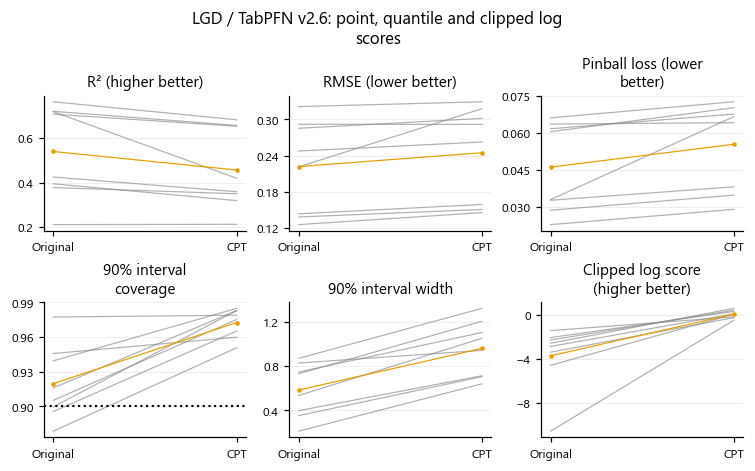

LGD. TabPFN v2.6 before and after the predefined CPT recipe. Thin lines connect each credit table's five-fold means; the colored line is their equal-table mean. The dotted coverage line marks the nominal 90% level. Log scores use the historical per-row NLL replacement/clipping at ±100 nats; they are not uncapped likelihood estimates.

In [6]:
for track, values in studies.items():
    main = next(run for e, arm, run in values if e == 1)
    cp.show(sink, rv.plot_secondary_effects(catalogs[track]['credit', sy.PRIMARY[track]], catalogs[track]['credit', sy.SECONDARY[track]], track), track=track)
    cp.show(sink, sy.plot_reference_tables(catalogs[track]['credit', sy.PRIMARY[track]], track), track=track)
    cp.show(sink, finish.plot_uncertainty(main), track=track)
    report.table(track.upper() + ' all reference metrics', ce.reference_profiles(main))
    if track == 'pd':
        cp.show(sink, dg.plot_calibration_overview(main), track=track)
    diagnostic, support = pred.analyze(main, reference=True)
    report.table(track.upper() + ' prediction coverage', support)
    report.table(track.upper() + ' paired prediction diagnostics', diagnostic)
    cp.show(sink, pred.plot_diagnostics(diagnostic, track, coverage=support), track=track)
    if track == 'lgd':
        cp.show(sink, finish.plot_lgd_distribution(main), track=track)
report.add('5. The fixed reference: named tables and prediction quality', 'The reference is fixed independently of held-out outcomes. Named-table plots and saved-prediction diagnostics show whether the mean hides heterogeneity. Signed residuals are not the theoretical model bias; table-bootstrap intervals are conditional on these fitted checkpoints.')

## 6. Cost, complete numerical results and conclusions

Transfer is model-, task- and recipe-dependent. Compare paired changes rather than raw scores across different inference settings. Missing model additions are explicit. These empirical questions were organized after results were visible; they are not preregistered directional hypotheses.

In [7]:
for track, values in studies.items():
    primary = catalogs[track]['credit', sy.PRIMARY[track]]
    report.table(track.upper() + ' recorded cost', sy.costs(values))
    for (domain, metric), data in catalogs[track].items():
        report.table(track.upper() + ' all named-table pairs: ' + domain + ' ' + metric, data)
report.add('6. Cost, complete numerical results and conclusions', 'Transfer is model-, task- and recipe-dependent. Compare paired changes rather than raw scores across different inference settings. Missing model additions are explicit. These empirical questions were organized after results were visible; they are not preregistered directional hypotheses.')

,base,learning_rate,l2sp_lambda,frozen,sampling,experiment,arm,gpu_hours,partitions
0,TabICLv2,3.000000e-07,0.000,False,one_sample,1,None,6.423640,4
1,TabICLv2,3.000000e-07,0.000,True,one_sample,1,None,6.194608,4
2,TabICLv2,3.000000e-07,0.003,False,one_sample,1,None,6.592852,4
3,TabICLv2,3.000000e-07,0.003,True,one_sample,1,None,6.241242,4
4,TabICLv2,1.000000e-06,0.000,False,one_sample,1,None,6.419076,4
...,...,...,...,...,...,...,...,...,...
63,TabPFN v3,3.000000e-05,0.003,True,one_sample,1,None,5.359692,4
64,TabICLv2,3.000000e-07,0.003,False,one_sample,2,None,6.601100,4
65,TabPFN v2,3.000000e-07,0.003,False,one_sample,2,None,5.585670,4
66,TabPFN v2.6,3.000000e-07,0.003,False,one_sample,2,None,4.821530,4


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
17,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,Bondora Peer-to-Peer,0.897219,0.893602,-0.003617,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
18,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,Cobranded,0.842712,0.841679,-0.001034,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
19,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,Credit Risk,0.955257,0.937192,-0.018065,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
20,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,GMSC,0.867210,0.864789,-0.002421,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
21,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,German Credit,0.790140,0.751390,-0.038751,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1151,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropPD2,0.657296,0.659135,0.001839,5,5,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,roc_auc,credit,Reference · seed 43,False,E2 Reference · seed 43
1152,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,SBA Loans Case,0.989833,0.990265,0.000432,5,3,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,roc_auc,credit,Reference · seed 43,False,E2 Reference · seed 43
1153,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Taiwan Credit Card,0.789665,0.789742,0.000077,5,3,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,roc_auc,credit,Reference · seed 43,False,E2 Reference · seed 43
1154,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Thomas,0.651588,0.653184,0.001597,5,3,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,roc_auc,credit,Reference · seed 43,False,E2 Reference · seed 43


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
17,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,Bondora Peer-to-Peer,0.080427,0.081775,-0.001348,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
18,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,Cobranded,0.130724,0.131295,-0.000571,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
19,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,Credit Risk,0.049369,0.058145,-0.008776,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
20,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,GMSC,0.049082,0.050075,-0.000993,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
21,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,German Credit,0.162387,0.177413,-0.015026,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1151,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropPD2,0.082365,0.082230,0.000135,5,5,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,brier_score,credit,Reference · seed 43,False,E2 Reference · seed 43
1152,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,SBA Loans Case,0.033251,0.032354,0.000897,5,4,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,brier_score,credit,Reference · seed 43,False,E2 Reference · seed 43
1153,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Taiwan Credit Card,0.133059,0.132839,0.000221,5,5,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,brier_score,credit,Reference · seed 43,False,E2 Reference · seed 43
1154,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,Thomas,0.183508,0.183179,0.000329,5,3,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,brier_score,credit,Reference · seed 43,False,E2 Reference · seed 43


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
4,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46905,0.845801,0.829129,-0.016672,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
5,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46947,0.936670,0.931692,-0.004978,20,1,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
6,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46952,0.940093,0.934745,-0.005347,20,5,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
7,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46956,0.776168,0.751324,-0.024843,20,3,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
20,tabicl-trained__tabicl-v2__lr1e-06__l2sp0.003,TabICLv2,openml_46905,0.845801,0.841191,-0.004610,20,2,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,roc_auc,ood,LR 1e-06 · λ 0.003,False,Grid all · LR 1e-06 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
267,tabpfn-trained__v2.6-default__lr3e-07__l2sp0.003,v2.6-default,openml_46956,0.772788,0.772657,-0.000131,20,10,4,TabPFN v2.6,...,one_sample,Full CPT,2,Seed 43,None,roc_auc,ood,Reference · seed 43,False,E2 Reference · seed 43
268,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,openml_46905,0.841379,0.846026,0.004647,20,20,4,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,roc_auc,ood,Reference · seed 43,False,E2 Reference · seed 43
269,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,openml_46947,0.937855,0.937354,-0.000500,20,4,4,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,roc_auc,ood,Reference · seed 43,False,E2 Reference · seed 43
270,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,openml_46952,0.936632,0.936014,-0.000618,20,8,4,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,roc_auc,ood,Reference · seed 43,False,E2 Reference · seed 43


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
4,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46905,0.040409,0.044512,-0.004102,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
5,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46947,0.067741,0.070005,-0.002264,20,1,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
6,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46952,0.085743,0.092296,-0.006554,20,1,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
7,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46956,0.056575,0.058508,-0.001933,20,4,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
20,tabicl-trained__tabicl-v2__lr1e-06__l2sp0.003,TabICLv2,openml_46905,0.040409,0.042002,-0.001592,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,brier_score,ood,LR 1e-06 · λ 0.003,False,Grid all · LR 1e-06 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
267,tabpfn-trained__v2.6-default__lr3e-07__l2sp0.003,v2.6-default,openml_46956,0.056689,0.056685,0.000004,20,8,4,TabPFN v2.6,...,one_sample,Full CPT,2,Seed 43,None,brier_score,ood,Reference · seed 43,False,E2 Reference · seed 43
268,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,openml_46905,0.040370,0.040199,0.000171,20,17,4,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,brier_score,ood,Reference · seed 43,False,E2 Reference · seed 43
269,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,openml_46947,0.066908,0.067155,-0.000247,20,4,4,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,brier_score,ood,Reference · seed 43,False,E2 Reference · seed 43
270,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,openml_46952,0.087798,0.089004,-0.001205,20,6,4,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,brier_score,ood,Reference · seed 43,False,E2 Reference · seed 43


,base,learning_rate,l2sp_lambda,frozen,sampling,experiment,arm,gpu_hours,partitions
0,TabICLv2,3.000000e-07,0.000,False,one_sample,1,None,2.153376,4
1,TabICLv2,3.000000e-07,0.000,True,one_sample,1,None,2.022735,4
2,TabICLv2,3.000000e-07,0.003,False,one_sample,1,None,2.306132,4
3,TabICLv2,3.000000e-07,0.003,True,one_sample,1,None,2.078621,4
4,TabICLv2,1.000000e-06,0.000,False,one_sample,1,None,2.154600,4
...,...,...,...,...,...,...,...,...,...
63,TabPFN v3,3.000000e-05,0.003,True,one_sample,1,None,2.132561,4
64,TabICLv2,3.000000e-07,0.003,False,one_sample,2,None,2.304418,4
65,TabPFN v2,3.000000e-07,0.003,False,one_sample,2,None,2.554024,4
66,TabPFN v2.6,3.000000e-07,0.003,False,one_sample,2,None,3.336288,4


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
8,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,Freddie Mac,0.383912,0.237114,-0.146798,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
9,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,LendingClub (LGD),0.763625,0.732795,-0.030830,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
10,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,PropLGD1,0.642400,0.465060,-0.177340,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
11,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,PropLGD2,0.727264,0.703598,-0.023667,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
12,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,PropLGD3,0.212188,0.202809,-0.009379,5,1,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD2,0.734083,0.722518,-0.011565,5,0,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,r2,credit,Reference · seed 43,False,E2 Reference · seed 43
540,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD3,0.211298,0.213531,0.002233,5,3,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,r2,credit,Reference · seed 43,False,E2 Reference · seed 43
541,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD4,0.422376,0.422860,0.000484,5,2,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,r2,credit,Reference · seed 43,False,E2 Reference · seed 43
542,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD5,0.376603,0.374739,-0.001863,5,2,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,r2,credit,Reference · seed 43,False,E2 Reference · seed 43


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
8,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,Freddie Mac,0.249757,0.277914,-0.112874,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
9,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,LendingClub (LGD),0.125315,0.133271,-0.064244,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
10,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,PropLGD1,0.249361,0.304984,-0.223104,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
11,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,PropLGD2,0.141589,0.147596,-0.042436,5,0,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
12,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,PropLGD3,0.291811,0.293586,-0.005980,5,1,1,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,credit,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
539,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD2,0.139827,0.142867,-0.021900,5,0,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,rmse,credit,Reference · seed 43,False,E2 Reference · seed 43
540,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD3,0.291974,0.291566,0.001344,5,3,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,rmse,credit,Reference · seed 43,False,E2 Reference · seed 43
541,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD4,0.286148,0.286189,-0.000758,5,2,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,rmse,credit,Reference · seed 43,False,E2 Reference · seed 43
542,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,PropLGD5,0.321604,0.322070,-0.001384,5,2,1,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,rmse,credit,Reference · seed 43,False,E2 Reference · seed 43


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
4,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46904,0.974136,0.964768,-0.009369,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
5,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46917,0.947698,0.936025,-0.011673,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
6,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46949,0.765400,0.719218,-0.046182,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
7,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46961,0.931251,0.881867,-0.049384,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
20,tabicl-trained__tabicl-v2__lr1e-06__l2sp0.003,TabICLv2,openml_46904,0.974136,0.972138,-0.001998,20,4,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,r2,ood,LR 1e-06 · λ 0.003,False,Grid all · LR 1e-06 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
267,tabpfn-trained__v2.6-default__lr3e-07__l2sp0.003,v2.6-default,openml_46961,0.927464,0.873929,-0.053535,20,0,4,TabPFN v2.6,...,one_sample,Full CPT,2,Seed 43,None,r2,ood,Reference · seed 43,False,E2 Reference · seed 43
268,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,openml_46904,0.979378,0.970856,-0.008522,20,0,4,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,r2,ood,Reference · seed 43,False,E2 Reference · seed 43
269,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,openml_46917,0.946745,0.943606,-0.003139,20,0,4,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,r2,ood,Reference · seed 43,False,E2 Reference · seed 43
270,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,openml_46949,0.775784,0.760143,-0.015641,20,0,4,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,r2,ood,Reference · seed 43,False,E2 Reference · seed 43


,method_dirname,base_short,test_dataset_id,original,adapted,effect,folds,folds_improved,partitions,base,...,sampling,approach,experiment,study,arm,metric,domain,setting,reference,config
4,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46904,1.105748,1.288336,-0.164933,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
5,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46917,3.786589,4.196855,-0.112273,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
6,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46949,2.963379,3.233038,-0.091018,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
7,tabicl-trained__tabicl-v2__lr1e-05__l2sp0.003,TabICLv2,openml_46961,8.980406,11.524366,-0.283456,20,0,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,ood,LR 1e-05 · λ 0.003,False,Grid all · LR 1e-05 · λ 0.003
20,tabicl-trained__tabicl-v2__lr1e-06__l2sp0.003,TabICLv2,openml_46904,1.105748,1.148503,-0.038772,20,4,4,TabICLv2,...,one_sample,Full CPT,1,Main grid,None,rmse,ood,LR 1e-06 · λ 0.003,False,Grid all · LR 1e-06 · λ 0.003
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
267,tabpfn-trained__v2.6-default__lr3e-07__l2sp0.003,v2.6-default,openml_46961,9.224439,12.141813,-0.316502,20,0,4,TabPFN v2.6,...,one_sample,Full CPT,2,Seed 43,None,rmse,ood,Reference · seed 43,False,E2 Reference · seed 43
268,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,openml_46904,0.986882,1.172945,-0.188798,20,0,4,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,rmse,ood,Reference · seed 43,False,E2 Reference · seed 43
269,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,openml_46917,3.818698,3.934202,-0.032098,20,0,4,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,rmse,ood,Reference · seed 43,False,E2 Reference · seed 43
270,tabpfn-trained__v3-default__lr3e-07__l2sp0.003,v3-default,openml_46949,2.897021,2.996223,-0.034246,20,0,4,TabPFN v3,...,one_sample,Full CPT,2,Seed 43,None,rmse,ood,Reference · seed 43,False,E2 Reference · seed 43


## Complete text summary

Every displayed table, plotted value and paper caption, in section order.

In [8]:
print(report.summary(sink))

RQ1: transfer and stability — final results

0. Evidence and interpretation
DATA: no external source selected.
Project: no external source selected.
Missing project records are unavailable evidence, not zero effects or failed training.
E1 learning rates and E2 training seeds are viewed together. E1 keeps full updates with L2-SP 0.003; RQ2 retains the complete factorial. Final evaluation averages five paired outer folds within table, then weights tables equally. AUC/R² gains are CPT minus original; Brier/RMSE gains reverse direction. RMSE gains here are relative percentages.

1. Coverage, protocols and unique evidence
Training completion and benchmark completion are separate. All results retain their own matched original checkpoint. The current inference-policy table governs cross-study TabICL comparisons; a pending FP32 refresh is not published evidence.

Table: PD unique trial inventory
CSV (first column: row index)
row,public_studies,campaign,base,status,unique_trials
0,"1,3,4",cpt_m